In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
wr.filterwarnings('ignore')

**Reading Dataset**

In [2]:
df = pd.read_csv("Data/WineQT.csv")
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

**Analysing the Data**

In [3]:
df.shape

(1143, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [5]:
set(df.quality)

{3, 4, 5, 6, 7, 8}

In [6]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


In [7]:
df.columns.tolist()

['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol',
 'quality',
 'Id']

**Checking Missing Values**

In [8]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

**Checking for the duplicate values**

In [9]:
df.nunique()

fixed acidity             91
volatile acidity         135
citric acid               77
residual sugar            80
chlorides                131
free sulfur dioxide       53
total sulfur dioxide     138
density                  388
pH                        87
sulphates                 89
alcohol                   61
quality                    6
Id                      1143
dtype: int64

**Univariate Analysis**

**1. Bar Plot for evaluating the count of the wine with its quality rate.**

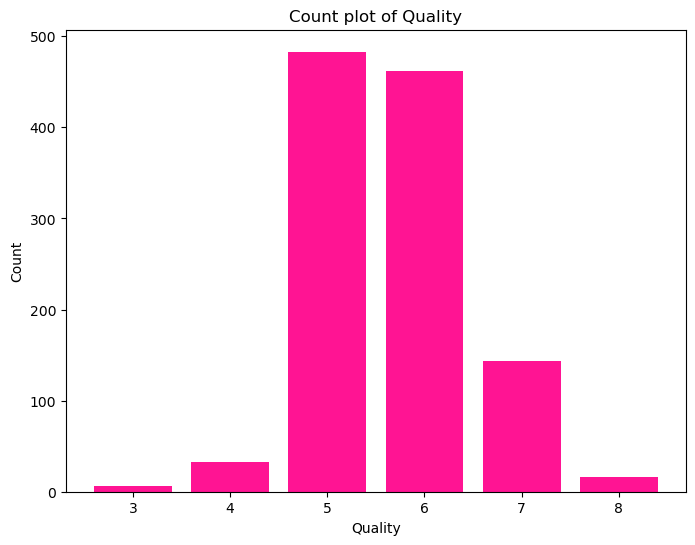

In [10]:
quality_counts = df['quality'].value_counts()
plt.figure(figsize=(8,6))
plt.bar(quality_counts.index, quality_counts, color='deeppink')
plt.xlabel('Quality')
plt.ylabel('Count')
plt.title('Count plot of Quality')
plt.show()

**2. Kernel density plot for understanding variance in the dataset**

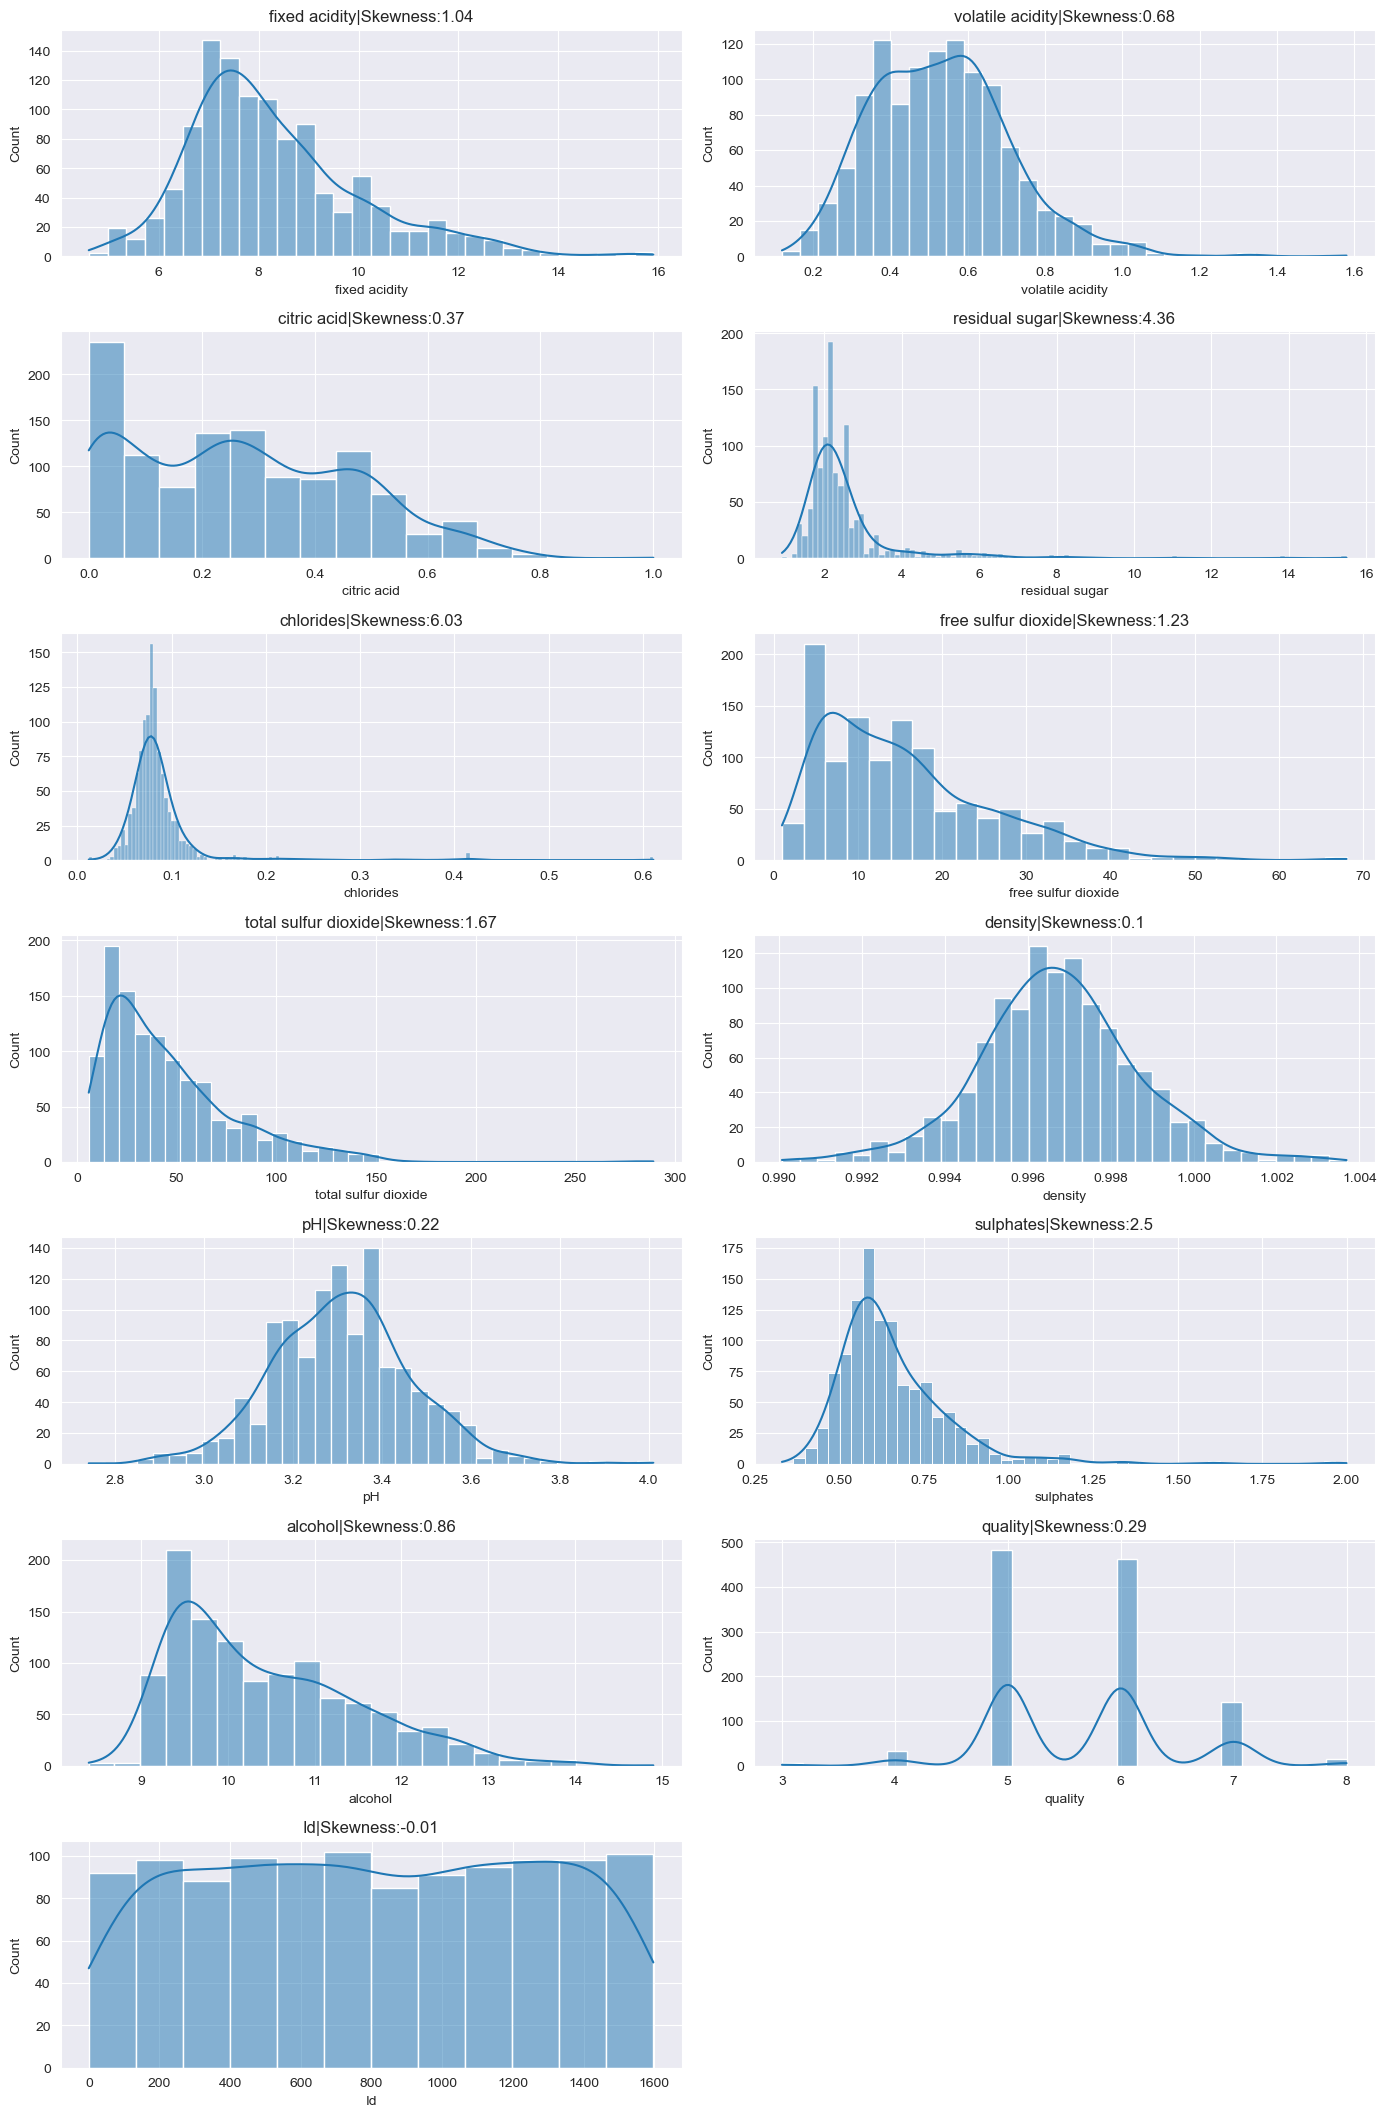

In [11]:
sns.set_style("darkgrid")
numerical_columns = df.select_dtypes(include=["int64","float64"]).columns
plt.figure(figsize = (14, len(numerical_columns)*3))
for idx, feature in enumerate(numerical_columns,1):
    plt.subplot(len(numerical_columns), 2, idx)
    sns.histplot(df[feature], kde= True)
    plt.title(f"{feature}|Skewness:{round(df[feature].skew(), 2)}")
plt.tight_layout()
plt.show()

**3. Swarm Plot for showing the outlier in the data**

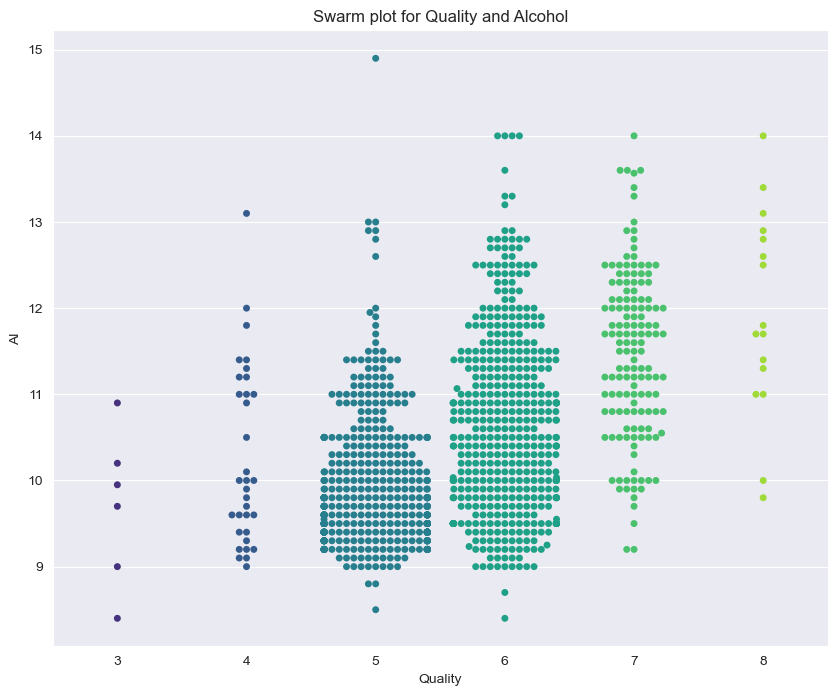

In [12]:
plt.figure(figsize=(10,8))
sns.swarmplot(data =df, x="quality", y="alcohol", palette="viridis")
plt.title("Swarm plot for Quality and Alcohol")
plt.xlabel("Quality")
plt.ylabel("Al")
plt.show()

**Bivariate Analysis**

**1. Pair Plot for showing the distribution of the individual variables**

<Figure size 1000x600 with 0 Axes>

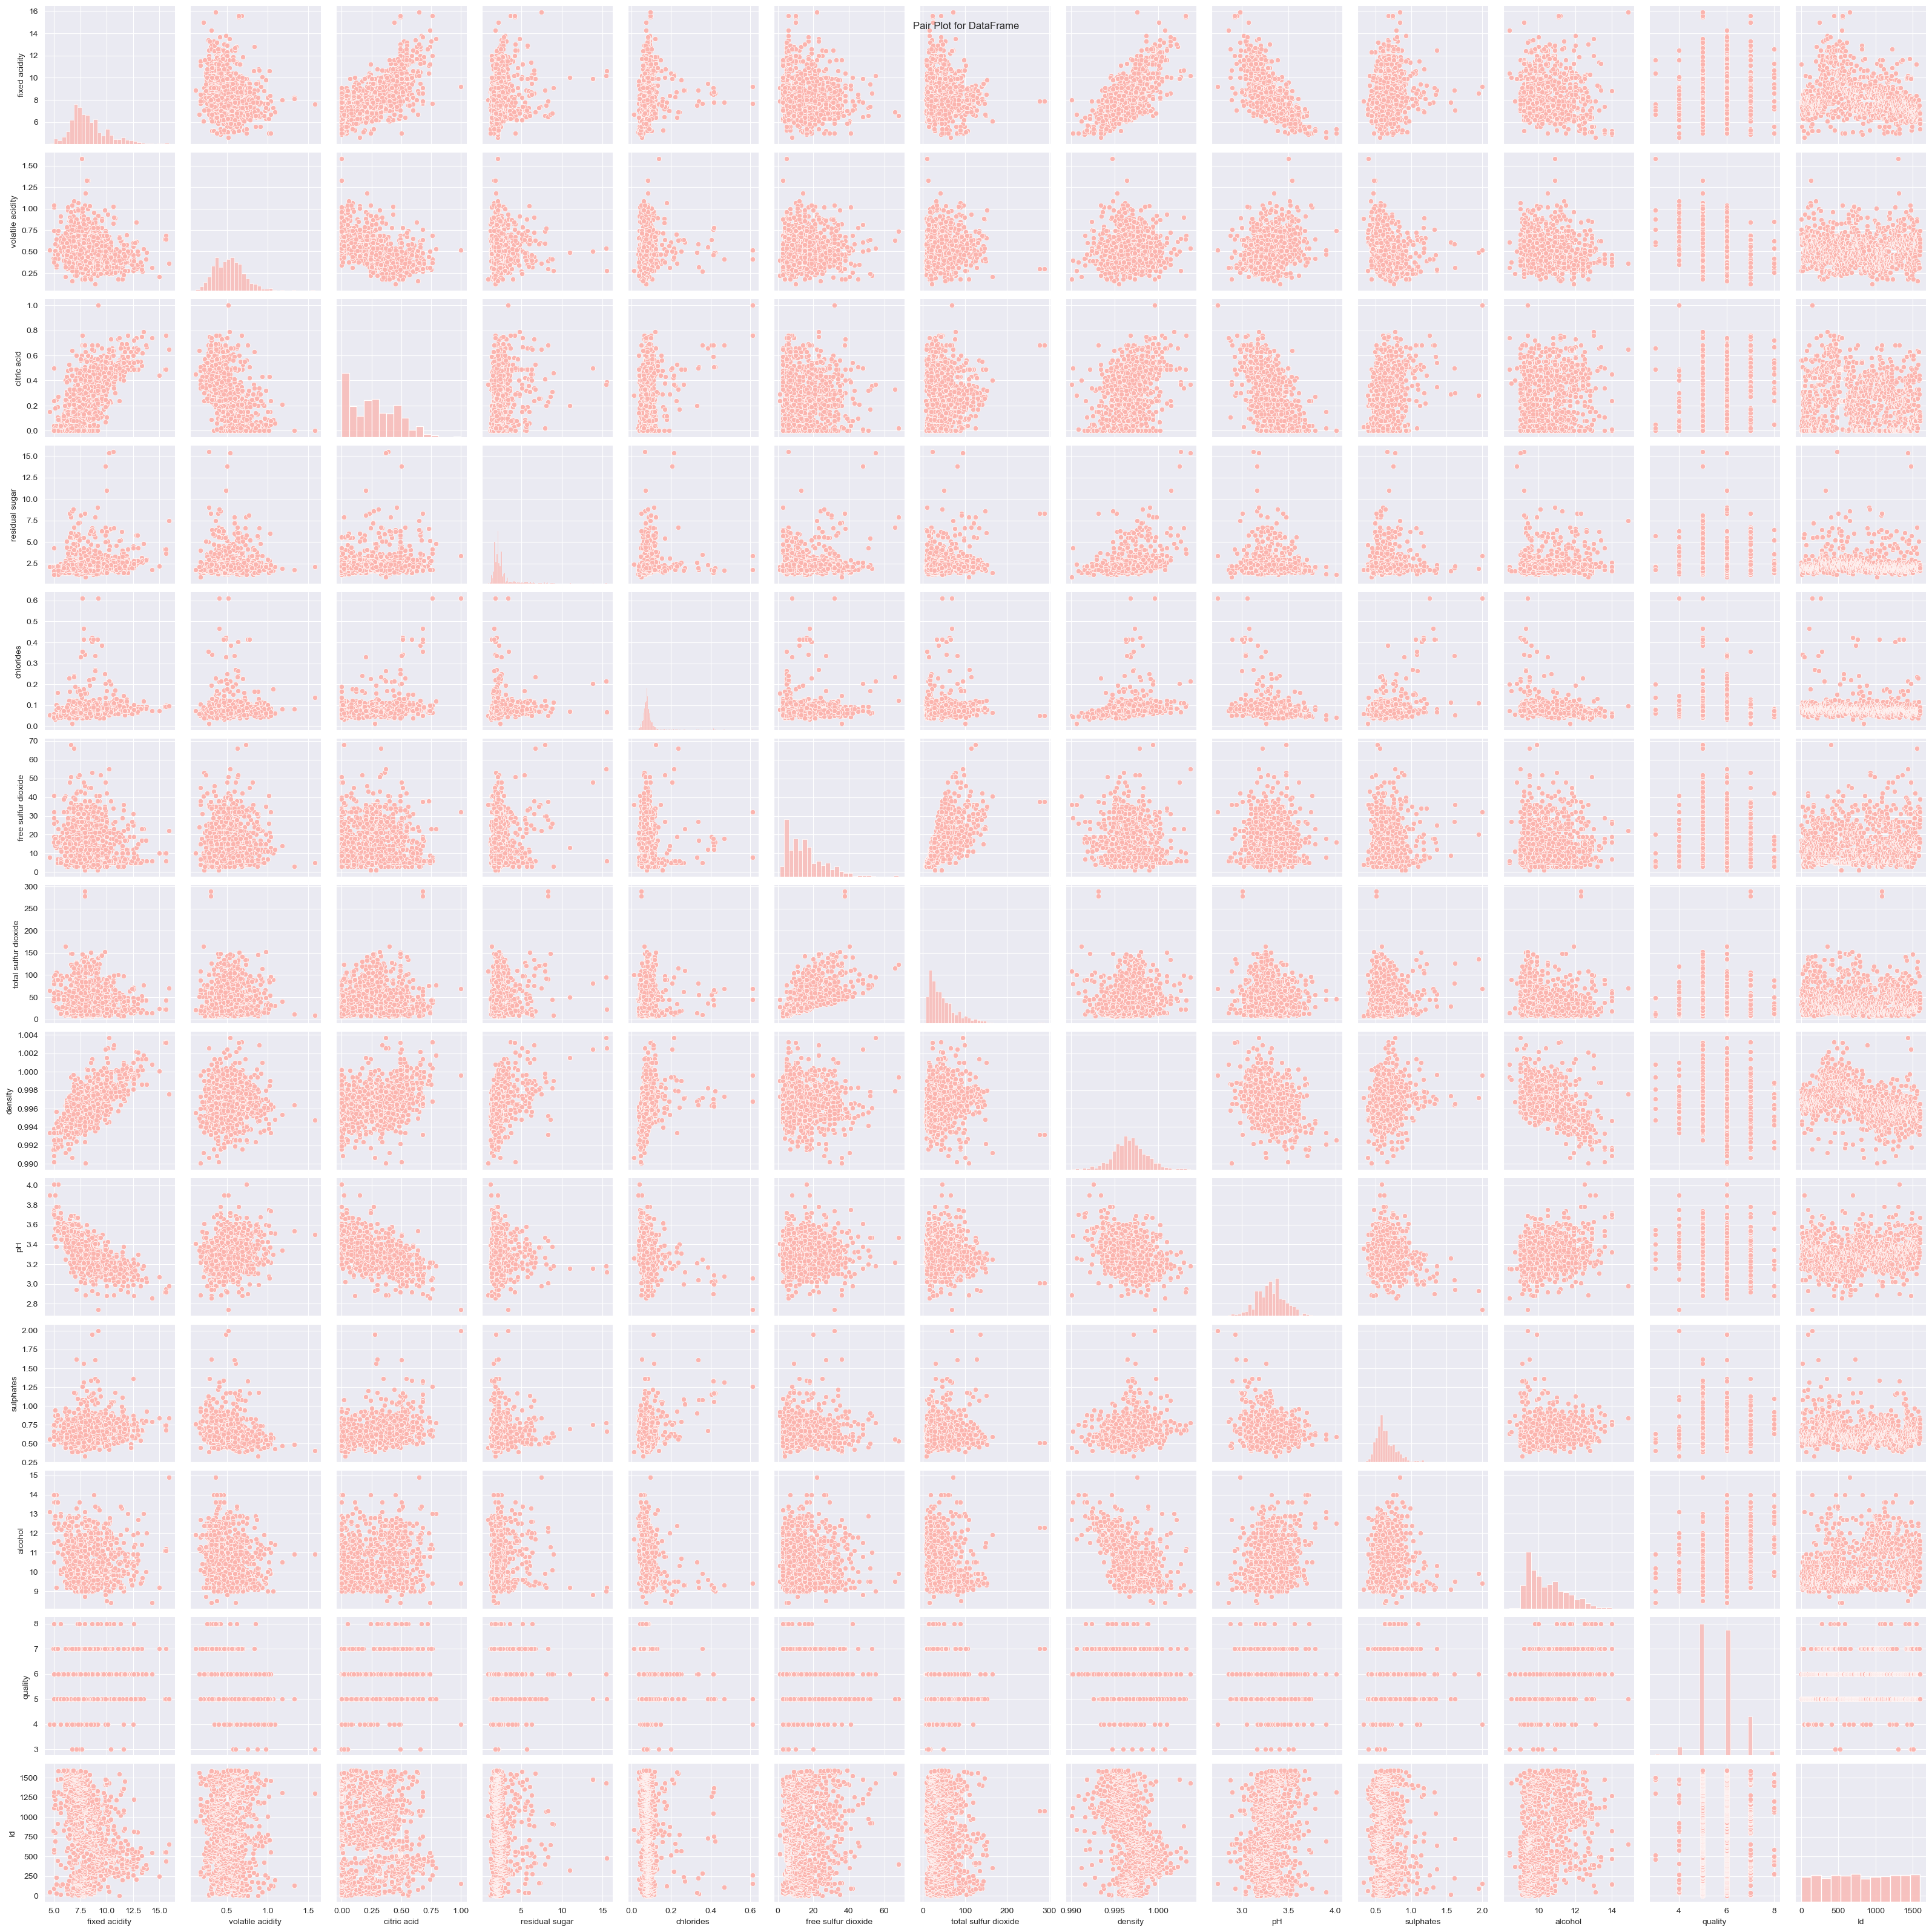

In [13]:
sns.set_palette("Pastel1")
plt.figure(figsize=(10,6))
sns.pairplot(df)
plt.suptitle('Pair Plot for DataFrame')
plt.show()

*If the plot is diagonal , histograms of kernel density plots shows the distribution of the individual variables.*
*If the scatter plot is in the lower triangle, it displays the relationship between the pairs of the variables.*
*If the scatter plots above and below the diagonal are mirror images indicating symmetry.*
*If the histogram plots are more centered, it represents the locations of peaks.*
*Skewness is found by observing whether the histogram is symmetrical or skewed to the left or right.*

**2. Violin Plot for examining the relationship between alcohol and Quality.**

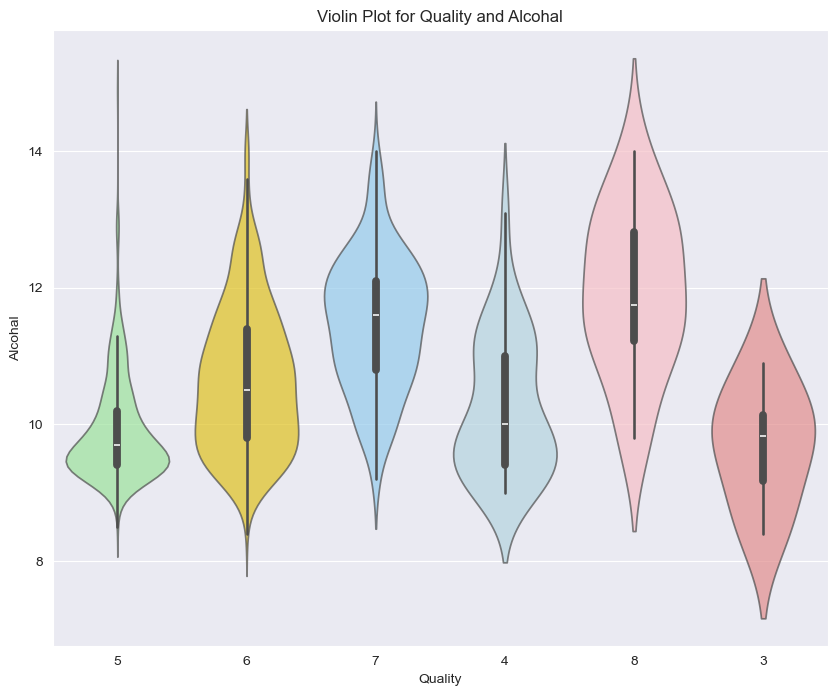

In [14]:
df['quality'] = df['quality'].astype(str)
plt.figure(figsize=(10,8))
sns.violinplot(x='quality', y='alcohol',data=df, palette={
    '3':'lightcoral', '4':'lightblue', '5':'lightgreen', '6':'gold', '7':'lightskyblue', '8':'lightpink'
}, alpha=0.7)
plt.title('Violin Plot for Quality and Alcohal')
plt.xlabel('Quality')
plt.ylabel('Alcohal')
plt.show()

*If the width is wider, it shows higher density suggesting more data points.*
*Symmetrical plot shows a balanced distribution.*
*Peak or bulge in the violin plot represents most common value in distribution.*
*Longer tails shows great variability.*
*Median line is the middle line inside the violin plot. It helps in understanding central tendencies.*

**3. Box Plot for examining the relationship between alcohol and Quality**

<Axes: xlabel='quality', ylabel='alcohol'>

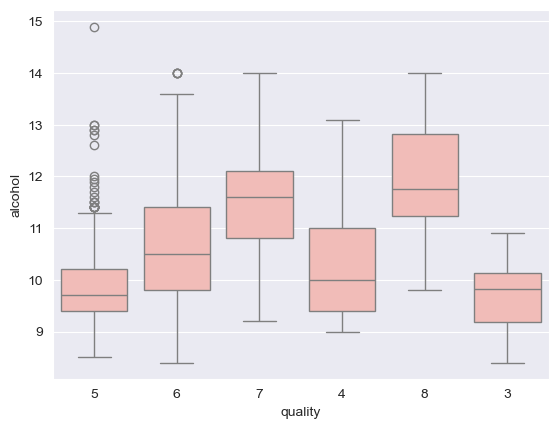

In [15]:
sns.boxplot(y='alcohol', x='quality', data=df)

Median line in the box shows central tendency.
Whiskers extend from box to the smallest and largest values within a specified range.
Individual points beyond the whiskers represents outliers.
A compact box shows low variability while a stretched box shows higher variability.

**Multivariate Analysis**

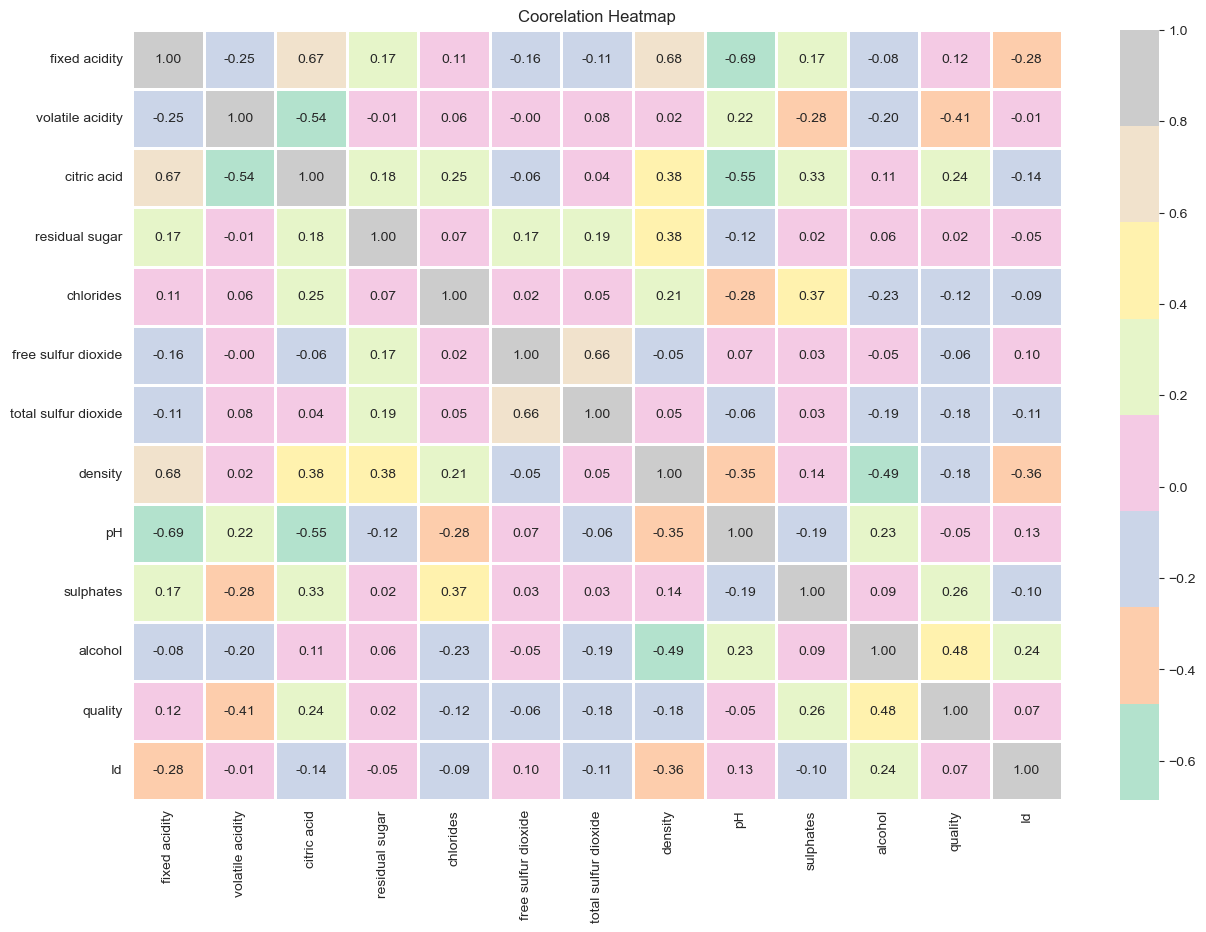

In [16]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(), annot=True, fmt= '.2f', cmap='Pastel2',linewidths = 2)
plt.title('Coorelation Heatmap')
plt.show()

Values close to +1 shows strong positive correlation, -1 shows a strong negative correlation and 0 suggests no linear correlation.

Darker colors signify strong correlation, while light colors represents weaker correlations.
Positive correlation variable move in same directions. As one increases, the other also increases.
Negative correlation variable move in opposite directions. An increase in one variable is associated with a decrease in the other.

**Detection of outliers using Z-score**

In [18]:
from scipy import stats
number = df.select_dtypes(include = ['number'])
z = np.abs(stats.zscore(number))
print(z)

      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.521580          0.939332     1.365027        0.466421   0.231395   
1          0.292593          1.941813     1.365027        0.050060   0.234247   
2          0.292593          1.273492     1.161568        0.171289   0.107253   
3          1.653789          1.399789     1.483400        0.466421   0.252560   
4          0.521580          0.939332     1.365027        0.466421   0.231395   
...             ...               ...          ...             ...        ...   
1138       1.151292          0.118842     0.703785        0.171289   0.231395   
1139       0.865059          0.493785     0.958109        0.466421   0.400719   
1140       1.208538          0.382399     0.958109        0.392638   0.064922   
1141       1.380278          0.103932     0.856379        0.245072   0.527712   
1142       1.380278          0.633019     0.754650        0.392638   0.252560   

      free sulfur dioxide  

**z>3(Threshold) -> This is an outlier**

In [20]:
print(np.where(z>3))

(array([  11,   13,   30,   31,   32,   59,   61,   64,   75,   75,   87,
         88,   96,   98,  103,  103,  103,  103,  114,  115,  129,  142,
        161,  161,  167,  170,  171,  182,  182,  200,  230,  231,  240,
        244,  249,  272,  275,  275,  278,  278,  287,  289,  311,  311,
        329,  339,  339,  348,  366,  388,  397,  397,  399,  399,  407,
        419,  421,  424,  430,  452,  453,  454,  460,  460,  462,  462,
        462,  485,  490,  490,  493,  514,  520,  538,  557,  572,  589,
        597,  598,  627,  627,  644,  648,  654,  655,  690,  714,  738,
        738,  756,  760,  760,  761,  761,  787,  831,  871,  890,  898,
        898,  914,  915,  919,  922,  931,  933,  934,  934,  935,  965,
        971,  973,  973,  975,  975, 1022, 1022, 1022, 1051, 1051, 1053,
       1053, 1066, 1111, 1111, 1111, 1122], dtype=int64), array([ 9,  4,  4,  9,  8,  9,  9,  9,  4,  9,  1,  1, 10, 10,  2,  4,  8,
        9,  3,  3,  4,  1,  4,  9,  4,  0,  0,  4,  9,  4,  3, 

**Remove those records whose z>3(outlier)**

In [21]:
new_data = df[(z<3).all(axis=1)]

In [22]:
new_data.shape

(1046, 13)

In [23]:
df.shape

(1143, 13)

**Data Spliting into feature(X) and target column(y)**

In [24]:
from sklearn.model_selection import train_test_split
X = new_data.drop(columns = 'quality')
y = new_data['quality']

In [25]:
X.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,4


In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

**Using Random Classifier**

In [27]:
from sklearn.ensemble import RandomForestClassifier
rf_classificationModel = RandomForestClassifier(n_estimators = 100)

In [28]:
rf_classificationModel.fit(X_train, y_train)

RandomForestClassifier()

**Prediction of data using random forest model**

In [29]:
y_pred = rf_classificationModel.predict(X_test)

In [30]:
y_pred

array(['6', '6', '7', '5', '6', '5', '6', '5', '5', '6', '6', '6', '5',
       '6', '6', '6', '5', '5', '5', '5', '5', '5', '7', '5', '5', '5',
       '5', '5', '6', '6', '6', '5', '5', '6', '5', '6', '6', '5', '6',
       '6', '6', '6', '5', '6', '6', '6', '6', '5', '5', '6', '6', '5',
       '5', '6', '6', '6', '6', '5', '6', '6', '5', '5', '6', '5', '7',
       '5', '6', '6', '7', '6', '6', '7', '6', '6', '6', '6', '5', '5',
       '6', '5', '6', '5', '5', '5', '5', '6', '6', '5', '6', '6', '5',
       '6', '6', '6', '6', '6', '6', '7', '7', '7', '6', '6', '5', '7',
       '6', '5', '5', '5', '6', '5', '5', '7', '6', '7', '6', '7', '6',
       '5', '5', '6', '5', '6', '5', '6', '5', '5', '5', '6', '6', '6',
       '7', '5', '6', '5', '5', '5', '6', '6', '5', '5', '5', '5', '6',
       '5', '5', '5', '5', '6', '5', '6', '6', '5', '5', '6', '5', '6',
       '5', '5', '5', '5', '5', '6', '6', '6', '7', '5', '6', '7', '6',
       '5', '6', '7', '5', '6', '5', '6', '6', '5', '7', '7', '7

**Data Evaluation on metrics**

In [31]:
from sklearn import metrics
print("Accuracy Score:",(metrics.accuracy_score(y_test, y_pred)))

Accuracy Score: 0.6476190476190476


**Cross Validation Score with K=5(KFold Strategy)**

In [32]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(RandomForestClassifier(n_estimators = 100), X,y, cv = 5)
cv_scores

array([0.43809524, 0.48803828, 0.57416268, 0.55502392, 0.5645933 ])

In [33]:
np.average(cv_scores)

0.523982683982684

**Hyperparameter Tuning using GridSearchCV and RandomizedSearchCV**

**1.GridSearchCV**

In [38]:
from sklearn.model_selection import GridSearchCV
grid_pram = {
    "n_estimators":[5,10,50,120,150],
    "criterion":['gini', 'entropy'],
    'max_depth':range(10),
    'min_samples_leaf':range(10)
    }

In [39]:
grid_search_rf = GridSearchCV(param_grid = grid_pram, cv=5, n_jobs=6, verbose=1, estimator = rf_classificationModel)

In [40]:
grid_search_rf.fit(X,y)

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(), n_jobs=6,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': range(0, 10),
                         'min_samples_leaf': range(0, 10),
                         'n_estimators': [5, 10, 50, 120, 150]},
             verbose=1)

In [57]:
# grid_search_rf.cv_results_

In [43]:
result_df = pd.DataFrame(grid_search_rf.cv_results_)
print(result_df[['params', 'mean_test_score','rank_test_score']])

                                                params  mean_test_score  \
0    {'criterion': 'gini', 'max_depth': 0, 'min_sam...              NaN   
1    {'criterion': 'gini', 'max_depth': 0, 'min_sam...              NaN   
2    {'criterion': 'gini', 'max_depth': 0, 'min_sam...              NaN   
3    {'criterion': 'gini', 'max_depth': 0, 'min_sam...              NaN   
4    {'criterion': 'gini', 'max_depth': 0, 'min_sam...              NaN   
..                                                 ...              ...   
995  {'criterion': 'entropy', 'max_depth': 9, 'min_...         0.544060   
996  {'criterion': 'entropy', 'max_depth': 9, 'min_...         0.543080   
997  {'criterion': 'entropy', 'max_depth': 9, 'min_...         0.567956   
998  {'criterion': 'entropy', 'max_depth': 9, 'min_...         0.552686   
999  {'criterion': 'entropy', 'max_depth': 9, 'min_...         0.564129   

     rank_test_score  
0                811  
1                811  
2                811  
3      

In [44]:
df = pd.DataFrame(grid_search_rf.cv_results_)
df

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_min_samples_leaf,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.002732,0.002438,0.000000,0.000000,gini,0,0,5,"{'criterion': 'gini', 'max_depth': 0, 'min_sam...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,811
1,0.000805,0.000986,0.000000,0.000000,gini,0,0,10,"{'criterion': 'gini', 'max_depth': 0, 'min_sam...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,811
2,0.002188,0.003461,0.000000,0.000000,gini,0,0,50,"{'criterion': 'gini', 'max_depth': 0, 'min_sam...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,811
3,0.000401,0.000802,0.000000,0.000000,gini,0,0,120,"{'criterion': 'gini', 'max_depth': 0, 'min_sam...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,811
4,0.001024,0.000900,0.000000,0.000000,gini,0,0,150,"{'criterion': 'gini', 'max_depth': 0, 'min_sam...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,811
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.022177,0.002680,0.004219,0.002679,entropy,9,9,5,"{'criterion': 'entropy', 'max_depth': 9, 'min_...",0.457143,0.521531,0.588517,0.564593,0.588517,0.544060,0.049873,539
996,0.032274,0.004623,0.003670,0.002593,entropy,9,9,10,"{'criterion': 'entropy', 'max_depth': 9, 'min_...",0.480952,0.531100,0.622010,0.550239,0.531100,0.543080,0.045668,579
997,0.162615,0.005082,0.005232,0.000674,entropy,9,9,50,"{'criterion': 'entropy', 'max_depth': 9, 'min_...",0.485714,0.574163,0.641148,0.564593,0.574163,0.567956,0.049415,41
998,0.400208,0.020979,0.012180,0.002970,entropy,9,9,120,"{'criterion': 'entropy', 'max_depth': 9, 'min_...",0.442857,0.564593,0.641148,0.531100,0.583732,0.552686,0.065513,301


In [46]:
dir(df)

['T',
 '_AXIS_LEN',
 '_AXIS_ORDERS',
 '_AXIS_TO_AXIS_NUMBER',
 '_HANDLED_TYPES',
 '__abs__',
 '__add__',
 '__and__',
 '__annotations__',
 '__array__',
 '__array_priority__',
 '__array_ufunc__',
 '__arrow_c_stream__',
 '__bool__',
 '__class__',
 '__contains__',
 '__copy__',
 '__dataframe__',
 '__dataframe_consortium_standard__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__divmod__',
 '__doc__',
 '__eq__',
 '__finalize__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__imod__',
 '__imul__',
 '__init__',
 '__init_subclass__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__module__',
 '__mul__',
 '__ne__',
 '__neg__',
 '__new__',
 '__nonzero__',
 '__or__',
 '__pandas_priority__',
 '__pos__',
 '__pow__',
 '__r

In [49]:
grid_search_rf.best_score_

0.5812212349054454

In [50]:
grid_search_rf.best_params_

{'criterion': 'gini', 'max_depth': 9, 'min_samples_leaf': 9, 'n_estimators': 5}

**2.RandomizedSearchCV**

In [56]:
from sklearn.model_selection import RandomizedSearchCV
rs = RandomizedSearchCV(RandomForestClassifier(n_estimators = 100),{
    "n_estimators":[5,10,50,100,120,150],
    "criterion":['gini', 'entropy'],
    "max_depth":range(10),
    "min_samples_leaf":range(10)
    },
    cv=5,
    return_train_score=False,
    n_iter = 2
)
rs.fit(X,y)
pd.DataFrame(rs.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_estimators,param_min_samples_leaf,param_max_depth,param_criterion,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.267413,0.020976,0.007481,0.000629,120,6,7,entropy,"{'n_estimators': 120, 'min_samples_leaf': 6, '...",0.471429,0.555024,0.626794,0.583732,0.598086,0.567013,0.053102,1
1,0.000867,0.000269,0.000000,0.000000,150,8,0,gini,"{'n_estimators': 150, 'min_samples_leaf': 8, '...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,2


Using RandomizedSearchCV insted of GridSearchCV(cuz it takes alot of time and also computationaly expensive but Randomised used some random number and give best para...)